In [1]:

from pathlib import Path
import pandas as pd

# Find the project root
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

# Define column names
columns = (
    ["engine_id", "cycle"]
    + [f"setting_{i}" for i in range(1, 4)]
    + [f"sensor_{i}" for i in range(1, 22)]
)

# Load training dataset
file_path = project_root / "data" / "raw" / "train_FD001.txt"

df = pd.read_csv(
    file_path,
    sep=r"\s+",
    header=None,
    names=columns
)

# First inspection
print("Dataset shape:", df.shape)
print("Number of engines:", df["engine_id"].nunique())
print("\nFirst five rows:")
print(df.head())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())


Dataset shape: (20631, 26)
Number of engines: 100

First five rows:
   engine_id  cycle  setting_1  setting_2  setting_3  sensor_1  sensor_2  \
0          1      1    -0.0007    -0.0004      100.0    518.67    641.82   
1          1      2     0.0019    -0.0003      100.0    518.67    642.15   
2          1      3    -0.0043     0.0003      100.0    518.67    642.35   
3          1      4     0.0007     0.0000      100.0    518.67    642.35   
4          1      5    -0.0019    -0.0002      100.0    518.67    642.37   

   sensor_3  sensor_4  sensor_5  ...  sensor_12  sensor_13  sensor_14  \
0   1589.70   1400.60     14.62  ...     521.66    2388.02    8138.62   
1   1591.82   1403.14     14.62  ...     522.28    2388.07    8131.49   
2   1587.99   1404.20     14.62  ...     522.42    2388.03    8133.23   
3   1582.79   1401.87     14.62  ...     522.86    2388.08    8133.83   
4   1582.85   1406.22     14.62  ...     522.19    2388.04    8133.80   

   sensor_15  sensor_16  sensor_17  

In [2]:

# 1. Check duplicate engine-cycle records
duplicates = df.duplicated(
    subset=["engine_id", "cycle"]
).sum()

# 2. Check missing values
missing = df.isna().sum().sum()

# 3. Check engine lifetime distribution
engine_cycles = df.groupby("engine_id")["cycle"].max()

print("Duplicate engine-cycle rows:", duplicates)
print("Missing values:", missing)
print("Minimum engine cycles:", engine_cycles.min())
print("Maximum engine cycles:", engine_cycles.max())
print("Average engine cycles:", engine_cycles.mean())

# 4. Identify constant columns
constant_cols = [
    col for col in df.columns
    if df[col].nunique() == 1
]

print("Constant columns:", constant_cols)


Duplicate engine-cycle rows: 0
Missing values: 0
Minimum engine cycles: 128
Maximum engine cycles: 362
Average engine cycles: 206.31
Constant columns: ['setting_3', 'sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']


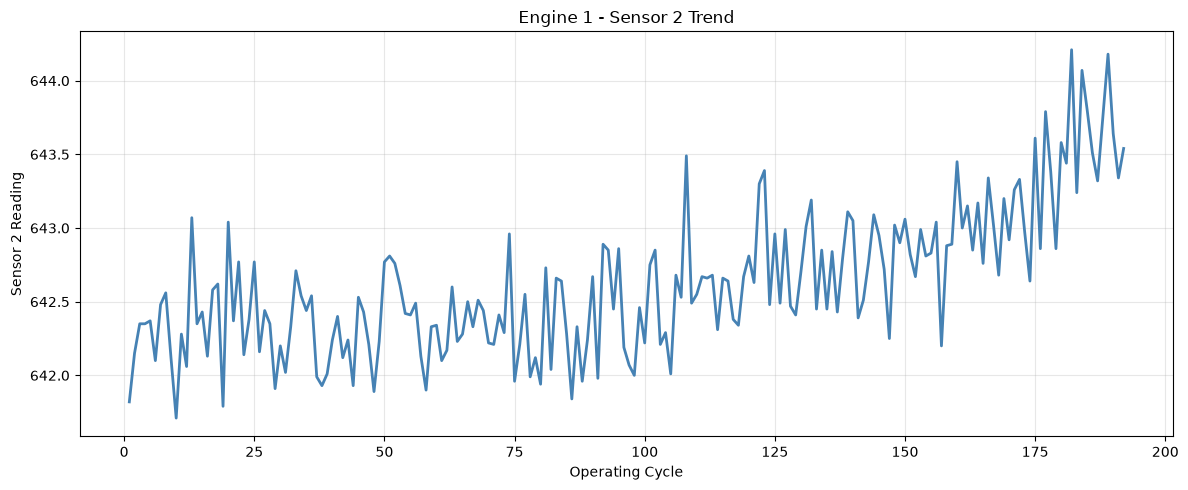

In [3]:

import matplotlib.pyplot as plt

# Select one engine
engine_1 = df[df["engine_id"] == 1]

# Plot a sensor over operating cycles
plt.figure(figsize=(12, 5))

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2"],
    color="steelblue",
    linewidth=2
)

plt.title("Engine 1 - Sensor 2 Trend")
plt.xlabel("Operating Cycle")
plt.ylabel("Sensor 2 Reading")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [4]:

cycle_check = df.groupby("engine_id")["cycle"].agg(
    ["min", "max", "count", "nunique"]
)

cycle_check["continuous"] = (
    (cycle_check["min"] == 1)
    & (cycle_check["max"] == cycle_check["count"])
    & (cycle_check["count"] == cycle_check["nunique"])
)

print(cycle_check.head())
print(
    "Engines with continuous cycles:",
    cycle_check["continuous"].sum()
)


           min  max  count  nunique  continuous
engine_id                                      
1            1  192    192      192        True
2            1  287    287      287        True
3            1  179    179      179        True
4            1  189    189      189        True
5            1  269    269      269        True
Engines with continuous cycles: 100


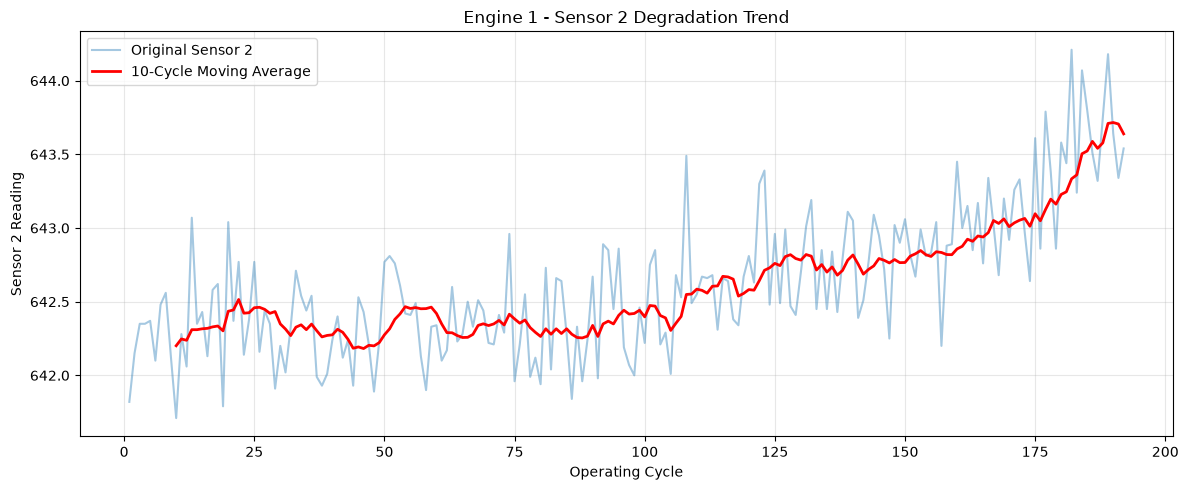

In [5]:

import matplotlib.pyplot as plt

engine_1 = df[df["engine_id"] == 1].copy()

# Calculate a 10-cycle moving average
engine_1["sensor_2_ma"] = (
    engine_1["sensor_2"]
    .rolling(window=10, min_periods=10)
    .mean()
)

plt.figure(figsize=(12, 5))

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2"],
    label="Original Sensor 2",
    alpha=0.4
)

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_2_ma"],
    label="10-Cycle Moving Average",
    color="red",
    linewidth=2
)

plt.title("Engine 1 - Sensor 2 Degradation Trend")
plt.xlabel("Operating Cycle")
plt.ylabel("Sensor 2 Reading")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


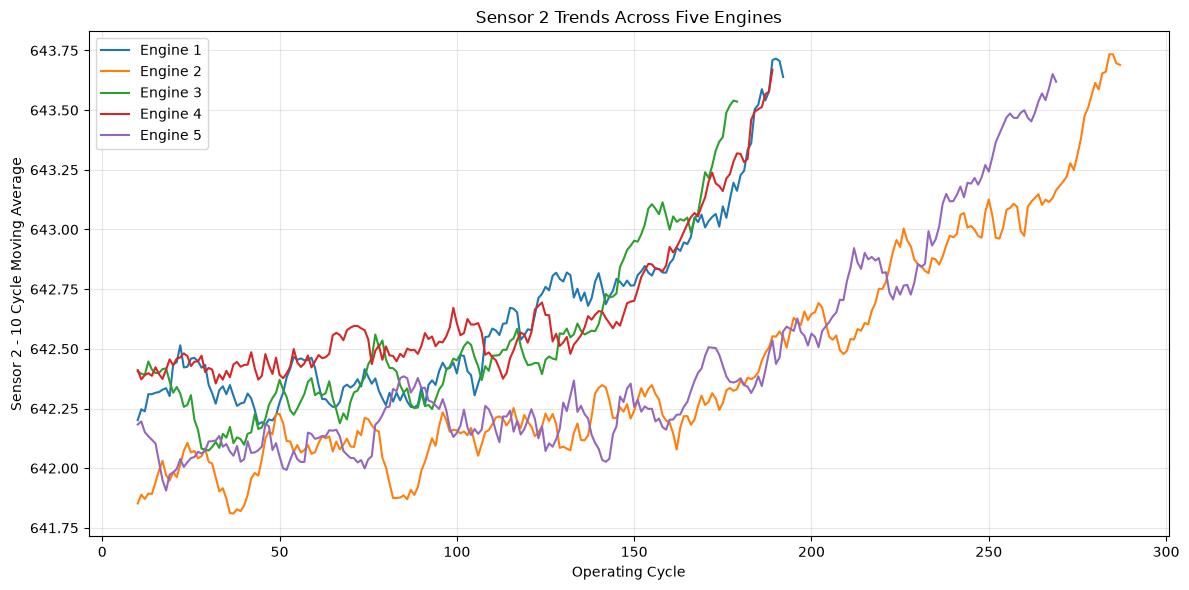

In [6]:

plt.figure(figsize=(12, 6))

for engine_id in [1, 2, 3, 4, 5]:

    engine_data = df[
        df["engine_id"] == engine_id
    ].copy()

    engine_data["moving_avg"] = (
        engine_data["sensor_2"]
        .rolling(window=10, min_periods=10)
        .mean()
    )

    plt.plot(
        engine_data["cycle"],
        engine_data["moving_avg"],
        label=f"Engine {engine_id}"
    )

plt.title("Sensor 2 Trends Across Five Engines")
plt.xlabel("Operating Cycle")
plt.ylabel("Sensor 2 - 10 Cycle Moving Average")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [7]:

engine_1 = df[df["engine_id"] == 1]

correlation = engine_1["cycle"].corr(
    engine_1["sensor_2"]
)

print(
    f"Correlation between cycle and Sensor 2: "
    f"{correlation:.3f}"
)


Correlation between cycle and Sensor 2: 0.693


In [8]:

import pandas as pd

sensor_cols = [
    f"sensor_{i}" for i in range(1, 22)
]

# Exclude constant sensors
variable_sensors = [
    col for col in sensor_cols
    if df[col].nunique() > 1
]

results = []

for engine_id, engine_data in df.groupby("engine_id"):
    for sensor in variable_sensors:
        correlation = engine_data["cycle"].corr(
            engine_data[sensor]
        )

        results.append({
            "engine_id": engine_id,
            "sensor": sensor,
            "correlation": correlation
        })

correlation_df = pd.DataFrame(results)

# Summarize across engines
sensor_summary = (
    correlation_df.groupby("sensor")
    .agg(
        mean_correlation=("correlation", "mean"),
        median_correlation=("correlation", "median"),
        mean_abs_correlation=(
            "correlation", lambda x: x.abs().mean()
        )
    )
    .sort_values(
        "mean_abs_correlation",
        ascending=False
    )
)

print(sensor_summary.round(3))


           mean_correlation  median_correlation  mean_abs_correlation
sensor                                                               
sensor_11             0.811               0.816                 0.811
sensor_12            -0.790              -0.811                 0.790
sensor_4              0.782               0.790                 0.782
sensor_7             -0.762              -0.783                 0.762
sensor_15             0.725               0.735                 0.725
sensor_21            -0.717              -0.730                 0.717
sensor_20            -0.714              -0.717                 0.714
sensor_13             0.687               0.774                 0.687
sensor_8              0.684               0.778                 0.684
sensor_14             0.224               0.670                 0.681
sensor_2              0.675               0.683                 0.675
sensor_17             0.673               0.681                 0.673
sensor_3            

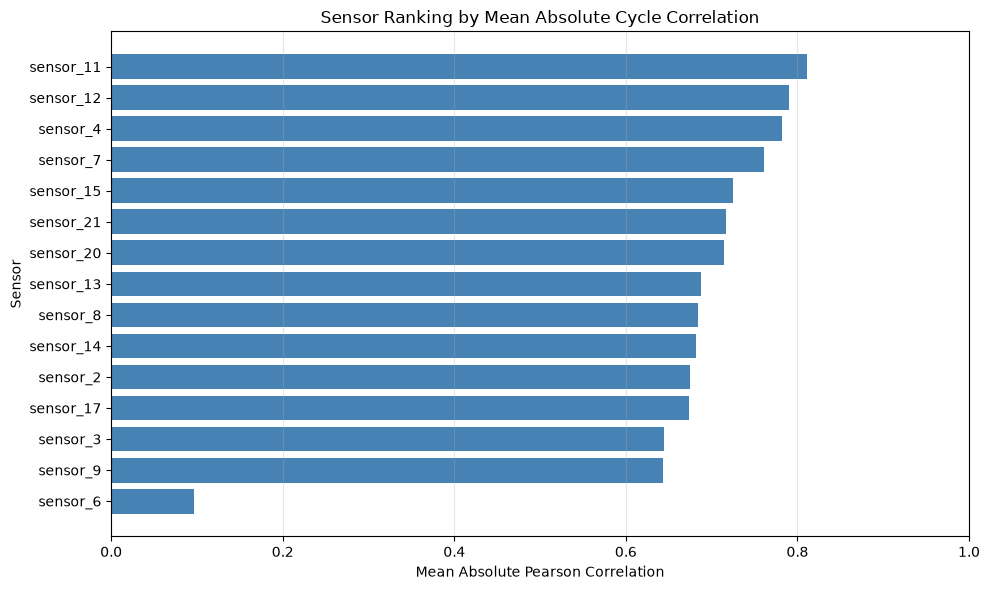

In [9]:

import matplotlib.pyplot as plt

ranking = sensor_summary.sort_values(
    "mean_abs_correlation"
)

plt.figure(figsize=(10, 6))

plt.barh(
    ranking.index,
    ranking["mean_abs_correlation"],
    color="steelblue"
)

plt.title(
    "Sensor Ranking by Mean Absolute Cycle Correlation"
)
plt.xlabel("Mean Absolute Pearson Correlation")
plt.ylabel("Sensor")
plt.xlim(0, 1)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:

# Select top five sensors
top_sensors = sensor_summary.head(5).index

for sensor in top_sensors:
    values = correlation_df.loc[
        correlation_df["sensor"] == sensor,
        "correlation"
    ]

    print(f"\n{sensor}")
    print(f"Mean correlation: {values.mean():.3f}")
    print(f"Minimum correlation: {values.min():.3f}")
    print(f"Maximum correlation: {values.max():.3f}")
    print(f"Positive trends: {(values > 0).sum()}")
    print(f"Negative trends: {(values < 0).sum()}")



sensor_11
Mean correlation: 0.811
Minimum correlation: 0.676
Maximum correlation: 0.870
Positive trends: 100
Negative trends: 0

sensor_12
Mean correlation: -0.790
Minimum correlation: -0.860
Maximum correlation: -0.643
Positive trends: 0
Negative trends: 100

sensor_4
Mean correlation: 0.782
Minimum correlation: 0.636
Maximum correlation: 0.836
Positive trends: 100
Negative trends: 0

sensor_7
Mean correlation: -0.762
Minimum correlation: -0.855
Maximum correlation: -0.593
Positive trends: 0
Negative trends: 100

sensor_15
Mean correlation: 0.725
Minimum correlation: 0.618
Maximum correlation: 0.813
Positive trends: 100
Negative trends: 0


In [11]:

import pandas as pd

selected_sensors = [
    "sensor_11",
    "sensor_12",
    "sensor_4",
    "sensor_7",
    "sensor_15"
]

# Provisional baseline: first 30 cycles
baseline = df[df["cycle"] <= 30].copy()

reference_stats = (
    baseline[selected_sensors]
    .agg(["mean", "std"])
    .T
)

reference_stats.columns = [
    "reference_mean",
    "reference_std"
]

reference_stats["lower_limit"] = (
    reference_stats["reference_mean"]
    - 2 * reference_stats["reference_std"]
)

reference_stats["upper_limit"] = (
    reference_stats["reference_mean"]
    + 2 * reference_stats["reference_std"]
)

print(reference_stats.round(3))


           reference_mean  reference_std  lower_limit  upper_limit
sensor_11          47.356          0.177       47.002       47.710
sensor_12         521.905          0.507      520.891      522.919
sensor_4         1402.831          5.932     1390.968     1414.695
sensor_7          553.948          0.624      552.700      555.195
sensor_15           8.418          0.026        8.366        8.471


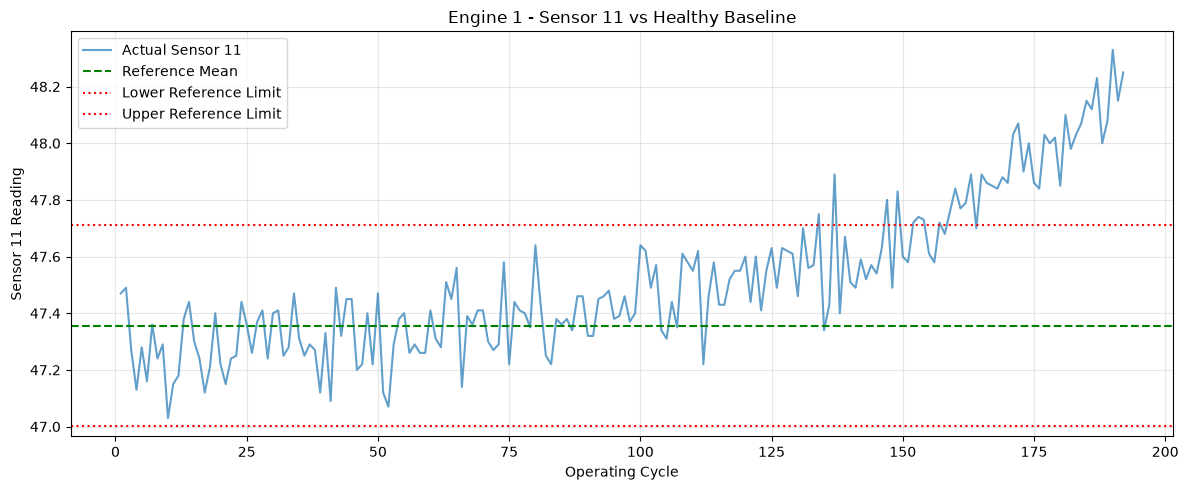

In [12]:

import matplotlib.pyplot as plt

engine_1 = df[df["engine_id"] == 1].copy()

sensor = "sensor_11"

ref_mean = reference_stats.loc[
    sensor, "reference_mean"
]
lower = reference_stats.loc[
    sensor, "lower_limit"
]
upper = reference_stats.loc[
    sensor, "upper_limit"
]

plt.figure(figsize=(12, 5))

plt.plot(
    engine_1["cycle"],
    engine_1[sensor],
    label="Actual Sensor 11",
    alpha=0.7
)

plt.axhline(
    ref_mean,
    color="green",
    linestyle="--",
    label="Reference Mean"
)

plt.axhline(
    lower,
    color="red",
    linestyle=":",
    label="Lower Reference Limit"
)

plt.axhline(
    upper,
    color="red",
    linestyle=":",
    label="Upper Reference Limit"
)

plt.title("Engine 1 - Sensor 11 vs Healthy Baseline")
plt.xlabel("Operating Cycle")
plt.ylabel("Sensor 11 Reading")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [13]:

sensor = "sensor_11"

ref_mean = reference_stats.loc[
    sensor, "reference_mean"
]
ref_std = reference_stats.loc[
    sensor, "reference_std"
]

engine_1 = df[df["engine_id"] == 1].copy()

engine_1["z_score"] = (
    (engine_1[sensor] - ref_mean)
    / ref_std
)

# Flag readings outside the reference band
engine_1["outside_reference"] = (
    engine_1["z_score"].abs() > 2
)

print(
    "Readings outside reference:",
    engine_1["outside_reference"].sum()
)

print(
    "Percentage outside reference:",
    round(
        engine_1["outside_reference"].mean() * 100,
        2
    ),
    "%"
)

print(engine_1[
    ["cycle", sensor, "z_score", "outside_reference"]
].tail(10))


Readings outside reference: 41
Percentage outside reference: 21.35 %
     cycle  sensor_11   z_score  outside_reference
182    183      48.03  3.809771               True
183    184      48.07  4.035896               True
184    185      48.15  4.488146               True
185    186      48.12  4.318552               True
186    187      48.23  4.940396               True
187    188      48.00  3.640177               True
188    189      48.08  4.092427               True
189    190      48.33  5.505708               True
190    191      48.15  4.488146               True
191    192      48.25  5.053458               True


In [17]:

import pandas as pd

engine_1 = (
    df[df["engine_id"] == 1]
    .sort_values("cycle")
    .copy()
)

sensor = "sensor_11"

upper_limit = reference_stats.loc[
    sensor, "upper_limit"
]

# Flag readings above upper limit
engine_1["above_limit"] = (
    engine_1[sensor] > upper_limit
)

# Five consecutive readings above limit
engine_1["sustained_deviation"] = (
    engine_1["above_limit"]
    .rolling(window=5, min_periods=5)
    .sum()
    .eq(5)
)

flagged_cycles = engine_1.loc[
    engine_1["sustained_deviation"],
    "cycle"
]

if not flagged_cycles.empty:
    first_detection = int(flagged_cycles.iloc[0])
    print(
        "First sustained deviation detected at cycle:",
        first_detection
    )
else:
    first_detection = None
    print("No sustained deviation detected.")


First sustained deviation detected at cycle: 163


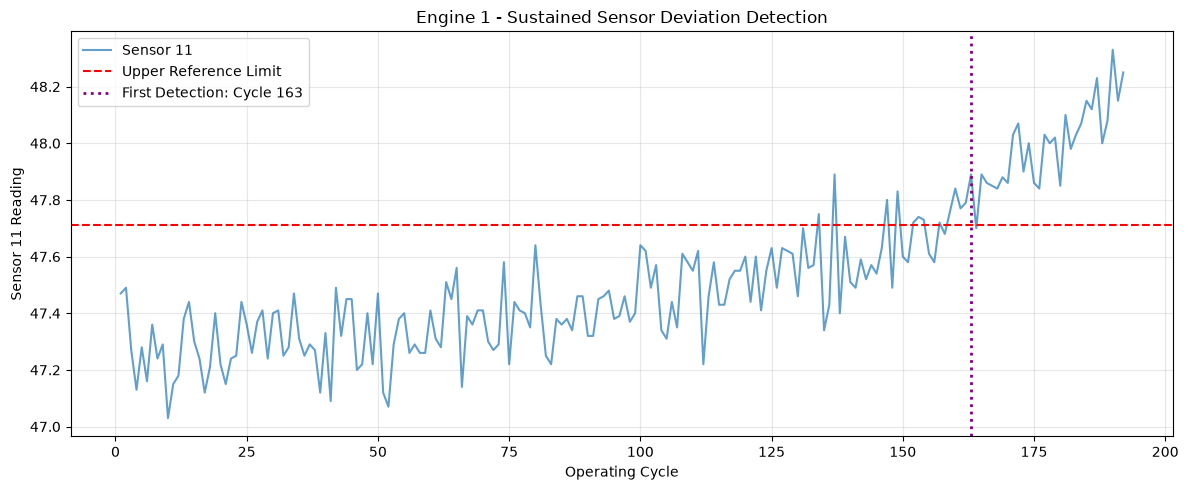

In [15]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    engine_1["cycle"],
    engine_1["sensor_11"],
    label="Sensor 11",
    alpha=0.7
)

plt.axhline(
    upper_limit,
    color="red",
    linestyle="--",
    label="Upper Reference Limit"
)

if first_detection is not None:
    plt.axvline(
        first_detection,
        color="purple",
        linestyle=":",
        linewidth=2,
        label=f"First Detection: Cycle {first_detection}"
    )

plt.title("Engine 1 - Sustained Sensor Deviation Detection")
plt.xlabel("Operating Cycle")
plt.ylabel("Sensor 11 Reading")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [16]:

failure_cycle = int(engine_1["cycle"].max())

if first_detection is not None:
    lead_time = failure_cycle - first_detection

    print("Engine failure cycle:", failure_cycle)
    print("First detection cycle:", first_detection)
    print("Detection lead time:", lead_time, "cycles")
else:
    print("No detection lead time available.")


Engine failure cycle: 192
First detection cycle: 163
Detection lead time: 29 cycles


In [18]:

import pandas as pd

sensor = "sensor_11"
upper_limit = reference_stats.loc[
    sensor, "upper_limit"
]

results = []

for engine_id, engine_data in df.groupby("engine_id"):

    engine_data = engine_data.sort_values("cycle").copy()

    # Identify readings above the reference limit
    engine_data["above_limit"] = (
        engine_data[sensor] > upper_limit
    )

    # Detect five consecutive exceedances
    engine_data["sustained_deviation"] = (
        engine_data["above_limit"]
        .rolling(window=5, min_periods=5)
        .sum()
        .eq(5)
    )

    flagged = engine_data.loc[
        engine_data["sustained_deviation"],
        "cycle"
    ]

    failure_cycle = int(engine_data["cycle"].max())

    if not flagged.empty:
        detection_cycle = int(flagged.iloc[0])
        lead_time = failure_cycle - detection_cycle
    else:
        detection_cycle = None
        lead_time = None

    results.append({
        "engine_id": engine_id,
        "failure_cycle": failure_cycle,
        "detection_cycle": detection_cycle,
        "lead_time": lead_time
    })

detection_results = pd.DataFrame(results)

print(detection_results.head(10))


   engine_id  failure_cycle  detection_cycle  lead_time
0          1            192              163         29
1          2            287              263         24
2          3            179              168         11
3          4            189              170         19
4          5            269              239         30
5          6            188              127         61
6          7            259              216         43
7          8            150              103         47
8          9            201              192          9
9         10            222              195         27


In [19]:

total_engines = len(detection_results)

detected_engines = (
    detection_results["detection_cycle"]
    .notna()
    .sum()
)

detection_rate = (
    detected_engines / total_engines * 100
)

print("Total engines:", total_engines)
print("Engines with alerts:", detected_engines)
print(f"Alert coverage: {detection_rate:.2f}%")

print(
    "Average lead time:",
    detection_results["lead_time"].mean()
)

print(
    "Median lead time:",
    detection_results["lead_time"].median()
)

print(
    "Minimum lead time:",
    detection_results["lead_time"].min()
)

print(
    "Maximum lead time:",
    detection_results["lead_time"].max()
)


Total engines: 100
Engines with alerts: 100
Alert coverage: 100.00%
Average lead time: 34.63
Median lead time: 29.0
Minimum lead time: 5
Maximum lead time: 95


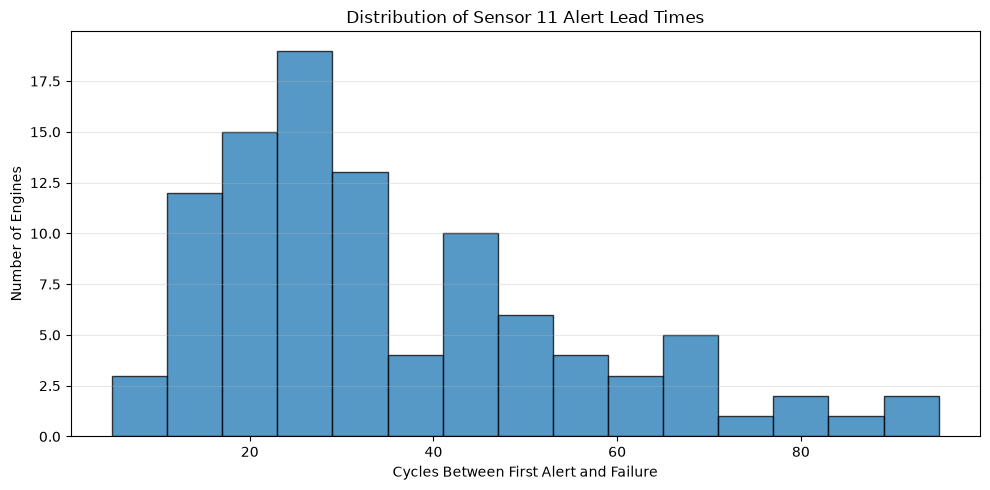

In [20]:

import matplotlib.pyplot as plt

lead_times = detection_results["lead_time"].dropna()

plt.figure(figsize=(10, 5))

plt.hist(
    lead_times,
    bins=15,
    edgecolor="black",
    alpha=0.75
)

plt.title("Distribution of Sensor 11 Alert Lead Times")
plt.xlabel("Cycles Between First Alert and Failure")
plt.ylabel("Number of Engines")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [21]:

import numpy as np
import pandas as pd

rng = np.random.default_rng(42)

engine_ids = df["engine_id"].unique()
rng.shuffle(engine_ids)

train_ids = engine_ids[:80]
validation_ids = engine_ids[80:]

train_df = df[df["engine_id"].isin(train_ids)].copy()
validation_df = df[
    df["engine_id"].isin(validation_ids)
].copy()

print("Training engines:", train_df["engine_id"].nunique())
print("Validation engines:", validation_df["engine_id"].nunique())


Training engines: 80
Validation engines: 20


In [22]:

sensor = "sensor_11"

baseline = train_df[train_df["cycle"] <= 30]

reference_mean = baseline[sensor].mean()
reference_std = baseline[sensor].std()

upper_limit = reference_mean + 2 * reference_std

print("Reference mean:", round(reference_mean, 3))
print("Reference std:", round(reference_std, 3))
print("Upper reference limit:", round(upper_limit, 3))


Reference mean: 47.352
Reference std: 0.174
Upper reference limit: 47.701


In [23]:

validation_results = []

for engine_id, engine_data in validation_df.groupby("engine_id"):

    engine_data = engine_data.sort_values("cycle").copy()

    above_limit = engine_data[sensor] > upper_limit

    sustained = (
        above_limit
        .rolling(window=5, min_periods=5)
        .sum()
        .eq(5)
    )

    detected = engine_data.loc[sustained, "cycle"]

    failure_cycle = int(engine_data["cycle"].max())

    if not detected.empty:
        detection_cycle = int(detected.iloc[0])
        lead_time = failure_cycle - detection_cycle
    else:
        detection_cycle = None
        lead_time = None

    validation_results.append({
        "engine_id": engine_id,
        "failure_cycle": failure_cycle,
        "detection_cycle": detection_cycle,
        "lead_time": lead_time
    })

validation_results = pd.DataFrame(validation_results)

print(validation_results)

print("\nValidation summary")
print("Total engines:", len(validation_results))
print(
    "Engines with alerts:",
    validation_results["detection_cycle"].notna().sum()
)
print(
    "Average lead time:",
    validation_results["lead_time"].mean()
)
print(
    "Median lead time:",
    validation_results["lead_time"].median()
)


    engine_id  failure_cycle  detection_cycle  lead_time
0           7            259              216         43
1           9            201              192          9
2          12            170              129         41
3          13            163              132         31
4          14            180              124         56
5          15            207              184         23
6          20            234              169         65
7          23            168              137         31
8          36            158              127         31
9          37            170              148         22
10         42            196              170         26
11         48            231              223          8
12         50            198              165         33
13         54            257              238         19
14         65            153              138         15
15         66            202              130         72
16         67            313   

In [24]:

from pathlib import Path

project_root = Path.cwd()

if project_root.name == "notebooks":
    project_root = project_root.parent

output_dir = project_root / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

# Save processed sensor data
df.to_csv(
    output_dir / "engine_sensor_data.csv",
    index=False
)

# Save validation results
validation_results.to_csv(
    output_dir / "validation_results.csv",
    index=False
)

print("Files saved successfully!")


Files saved successfully!
